# Gaussian noise, logical recovery, and the information a flag discards

A detector may report that one excitation survived even when its logical state changed. This notebook follows a specified physical channel through the actual dual-rail readout, then uses the paper's 32 frozen Hayden–Preskill sources to certify deterministic recovery. Two small constructions show why calibration and readout must be tied to the intended task.

**What is specified.** Each rail undergoes the same independent zero-mean one-mode Gaussian channel, $V\mapsto XVX^T+Y$, with $[q,p]=i$ and vacuum covariance $I/2$. A coherent measurement of **total** output number keeps the $N=1$ subspace; every other sector becomes a recorded erasure. Measuring which rail contains the photon would destroy the coherence being tested. These assumptions are essential. The input qubit need not be Gaussian.

The reduction is exact for this instrument and has no Fock cutoff. It does not identify an arbitrary moving or local Hawking detector with a particular pair $(X,Y)$.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
sys.path.insert(0, str(Path.cwd() / 'code'))
from receiver_extensions.paths import DATA, verify_inputs, save_result
manifest = verify_inputs()
print('Packaged input hashes verified:', ', '.join(manifest))


Packaged input hashes verified: frozen_inputs.npz, scalar_flux_grid_384.npz


## From the physical channel to five logical weights

Write $a,b,c,d$ for the four low-number transition probabilities, and $u,v$ for the two relevant coherence amplitudes. The retained operation is Pauli plus erasure:

$$w_I=(ad+|u|^2)/2,\quad w_Z=(ad-|u|^2)/2,\quad
w_X=(bc+|v|^2)/2,\quad w_Y=(bc-|v|^2)/2,\quad
w_E=1-ad-bc.$$

Independent identical parity-covariant rails already give this Pauli form. The additional Gaussian identity $ad-bc=|u|^2+|v|^2$ implies $w_X=w_Z$. The table checks loss, thermal loss, amplification, squeezing, phase conjugation, and a phase-sensitive mixed channel. An independent two-dimensional characteristic-function quadrature checks the six Fock entries against the closed Gaussian moments.


In [2]:
from receiver_extensions.gaussian_dualrail import gaussian_dualrail, product_error_bound
from receiver_extensions.gaussian_quadrature import direct_quadrature, rot
I = np.eye(2)
special = {
    'Identity': (I, np.zeros((2,2))),
    'Pure loss, eta=0.6': (np.sqrt(.6)*I, .2*I),
    'Thermal loss, eta=0.6, n=0.2': (np.sqrt(.6)*I, .4*.7*I),
    'Amplifier, G=1.7': (np.sqrt(1.7)*I, .35*I),
    'Squeezing, r=0.45': (np.diag(np.exp([.45,-.45])), np.zeros((2,2))),
    'Phase conjugator, G=0.4': (np.sqrt(.4)*np.diag([1,-1]), .7*I),
}
S1 = rot(.3) @ np.diag(np.exp([.2,-.2]))
S2 = np.diag(np.exp([-.15,.15])) @ rot(.2)
special['Phase-sensitive thermal loss'] = (np.sqrt(.6)*S2@S1, .4*.7*S2@S2.T)
channels, checks, rows = {}, [], []
for name, (X,Y) in special.items():
    c = gaussian_dualrail(X,Y)
    channels[name] = c
    vals = np.array([c[k] for k in ['a','b','c','d']] + [complex(*c['u']),complex(*c['v'])])
    residual = float(np.max(abs(vals-direct_quadrature(X,Y))))
    wick = c['a']*c['d']-c['b']*c['c']-abs(complex(*c['u']))**2-abs(complex(*c['v']))**2
    assert residual < 2e-8 and abs(wick)<1e-12
    assert abs(sum(c['pauli_weights'].values())+c['erasure']-1)<1e-12
    assert abs(c['pauli_weights']['X']-c['pauli_weights']['Z'])<1e-12
    checks.append(dict(channel=name, quadrature_residual=residual, Gaussian_identity_residual=float(wick)))
    rows.append(dict(channel=name, **c['pauli_weights'], erasure=c['erasure'], Bell_F=c['deterministic_bell_fidelity']))
display(pd.DataFrame(rows).set_index('channel').round(8))
print('Largest independent quadrature residual:', max(c['quadrature_residual'] for c in checks))


,I,X,Y,Z,erasure,Bell_F
channel,,,,,,
Identity,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000
"Pure loss, eta=0.6",0.600000,0.000000,0.000000,0.000000,0.400000,0.700000
"Thermal loss, eta=0.6, n=0.2",0.455130,0.014113,0.014113,0.014113,0.502532,0.580763
"Amplifier, G=1.7",0.203542,0.000000,0.000000,0.000000,0.796458,0.402656
"Squeezing, r=0.45",0.675686,0.000000,-0.000000,-0.000000,0.324314,0.756765
"Phase conjugator, G=0.4",0.104123,0.104123,-0.000000,0.104123,0.687630,0.276031
Phase-sensitive thermal loss,0.429323,0.016794,0.013082,0.016794,0.524007,0.560324


Largest independent quadrature residual: 9.325873406851315e-14


The all-trial single-qubit Bell overlap is $w_I+w_E/4$, using a fixed qubit output on erasure. The unrecorded Pauli weight $\epsilon=w_X+w_Y+w_Z$ is the half-diamond distance from the ideal erasure channel with the **same acceptance**. For independent carriers, $1-\prod_j(1-\epsilon_j)$ bounds the probability of any such error. The comparison must use the new channel's acceptance, not a former loss-only efficiency.

## Equal acceptance and Bell fidelity leave another task undetermined

Channels A and B are valid Gaussian channels. They have the same acceptance, all-trial Bell fidelity, and total unrecorded error. Yet their Pauli weights differ. For an equally likely pair of orthogonal states on axis $a$, the optimal all-trial correctness is $(1+|c_a|)/2$, including guesses on erasure. These are different experimental tasks from diary recovery.


In [3]:
from receiver_extensions.calibration_witness import calculate as matched_calibration
calibration = matched_calibration()
calibration_table = []
for name in ['A','B']:
    c = calibration[name]
    calibration_table.append(dict(channel=name, acceptance=c['survival'], Bell_F=c['deterministic_bell_fidelity'],
                                  error=c['unrecorded_pauli_error'], **c['pauli_weights'],
                                  binary_X=c['optimal_binary_success']['X'], binary_Y=c['optimal_binary_success']['Y']))
display(pd.DataFrame(calibration_table).set_index('channel').round(9))
print('Complete-positivity determinant surplus for B:', calibration['B_invariants']['cp_determinant_surplus'])
print('Matching residual:', calibration['matching_residual'])


,acceptance,Bell_F,error,I,X,Y,Z,binary_X,binary_Y
channel,,,,,,,,,
A,0.3584,0.4036,0.1152,0.2432,0.038400,0.03840,0.038400,0.602400,0.60240
B,0.3584,0.4036,0.1152,0.2432,0.051725,0.01175,0.051725,0.615725,0.57575


Complete-positivity determinant surplus for B: 752/10125
Matching residual: 5.551115123125783e-17


The missing datum can be supplied operationally: acceptance $p$ and signed correlations $c_X,c_Y$ reconstruct every weight in this Gaussian subclass, since $c_Z=c_X$. The numerical witness gives binary success $0.6024$ on every axis for A, versus $0.615725$ on X/Z and $0.57575$ on Y for B. It does **not** establish improved Hayden–Preskill recovery: the coarse certificates below deliberately agree for this pair.

## Applying the actual source tables

For each recorded carrier mask, the source table supplies $J=I(Q:X)/(2S(Q))$. The identity/erasure histories contribute a constructive lower certificate weighted by products of $w_I$ and $w_E$. Unrecorded-error histories have nonnegative Bell overlap, so discarding their contribution remains a lower bound. A constant output also guarantees $1/4$.

The upper certificate uses the ideal erasure channel at the *same* acceptance, because the noisy channel is its postprocessing. These are bounds on optimal deterministic decoding, not an implemented optimal decoder. The following supplied examples demonstrate the calculation on all 32 frozen source states; no example is asserted to be a locally derived Hawking receiver.


In [4]:
from receiver_extensions.recovery import certify
source = np.load(DATA/'frozen_inputs.npz')['source']
assert source.shape == (32,32,32)
examples = {
    'Pure loss (eta=0.6)': [channels['Pure loss, eta=0.6']]*5,
    'Thermal loss (eta=0.6, n=0.2)': [channels['Thermal loss, eta=0.6, n=0.2']]*5,
    'Matched A': [calibration['A']]*5,
    'Matched B': [calibration['B']]*5,
}
recovery = {name:certify(cs,source) for name,cs in examples.items()}
report = []
for name,r in recovery.items():
    report.append(dict(channel=name, full_early_floor=r['full_early']['lower_min'],
                       full_early_ceiling=r['full_early']['upper_max'],
                       no_early_ceiling=r['no_early']['upper_max'], any_error_bound=r['any_error_probability']))
display(pd.DataFrame(report).set_index('channel').round(8))
for observer in ['full_early','no_early']:
    for key in ['statewise_lower','statewise_upper']:
        np.testing.assert_allclose(recovery['Matched A'][observer][key], recovery['Matched B'][observer][key], atol=2e-14)
assert abs(product_error_bound(examples['Thermal loss (eta=0.6, n=0.2)'])-recovery['Thermal loss (eta=0.6, n=0.2)']['any_error_probability'])<1e-14
print('All 32 source states checked; matched A/B certificates agree.')


,full_early_floor,full_early_ceiling,no_early_ceiling,any_error_bound
channel,,,,
Pure loss (eta=0.6),0.932690,0.980967,0.387409,0.000000
"Thermal loss (eta=0.6, n=0.2)",0.699267,0.956154,0.347259,0.194507
Matched A,0.373413,0.885537,0.307785,0.457718
Matched B,0.373413,0.885537,0.307785,0.457718


All 32 source states checked; matched A/B certificates agree.


## Retaining an additional number sector changes recovery

A quantum-limited amplifier of gain $G$ and a pure-loss channel of transmission $G^{-3}$ have identical complete $N=1$-plus-erasure interfaces. Their discarded outputs differ. For the amplifier, the two-photon sector has probability $p_2=3(G-1)/G^4$. A coherent extraction from that sector yields the qubit channel

$$\mathcal D_2(\rho)=\tfrac23\rho+\tfrac13 I/2,$$

with Bell overlap $3/4$. Retaining and extracting this sector increases the attained deterministic score by $p_2/2$. This is an achievable improvement, not an optimization over all sectors. It spends additional coherent sector access and extraction resources; the amplifier also requires pump energy. The amplifier/cloning relation is established structure, here used to distinguish what two readout interfaces permit.


,G,p_one,p_two,coarse_F,sector_two_F,gain
0,1.0,1.000000,0.000000,1.000000,1.000000,0.000000
1,1.1,0.751315,0.204904,0.813486,0.915938,0.102452
2,1.5,0.296296,0.296296,0.472222,0.620370,0.148148
3,2.0,0.125000,0.187500,0.343750,0.437500,0.093750
4,3.0,0.037037,0.074074,0.277778,0.314815,0.037037
5,10.0,0.001000,0.002700,0.250750,0.252100,0.001350


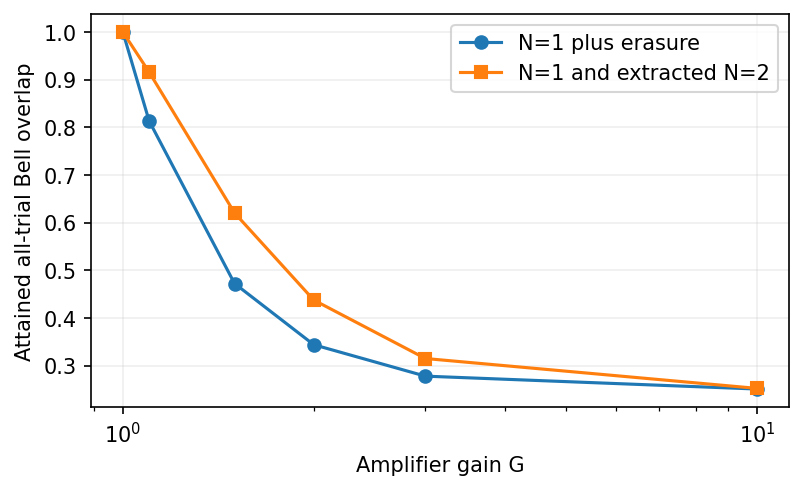

Conditional N=2 matrix residual: 2.220446049250313e-16


In [5]:
from receiver_extensions.sector_witness import calculate as additional_sector
sector = additional_sector()
G = 2.
amplifier = gaussian_dualrail(np.sqrt(G)*I, (G-1)*I/2)
loss = gaussian_dualrail(np.sqrt(G**-3)*I, (1-G**-3)*I/2)
np.testing.assert_allclose(list(amplifier['pauli_weights'].values())+[amplifier['erasure']],
                           list(loss['pauli_weights'].values())+[loss['erasure']], atol=1e-14)
assert sector['matrix_residual'] < 1e-14
sector_table = pd.DataFrame(sector['rows'])[['G','p_one','p_two','coarse_F','sector_two_F','gain']]
display(sector_table.round(8))
at_two = next(r for r in sector['rows'] if r['G']==2)
np.testing.assert_allclose([at_two['coarse_F'],at_two['sector_two_F']],[11/32,7/16],atol=1e-14)
fig, ax = plt.subplots(figsize=(6,3.4))
ax.plot(sector_table.G,sector_table.coarse_F,'o-',label='N=1 plus erasure')
ax.plot(sector_table.G,sector_table.sector_two_F,'s-',label='N=1 and extracted N=2')
ax.set(xlabel='Amplifier gain G',ylabel='Attained all-trial Bell overlap',xscale='log')
ax.legend(); ax.grid(alpha=.2); plt.show()
print('Conditional N=2 matrix residual:',sector['matrix_residual'])


The separation between the two curves is the recovery value of the otherwise discarded two-photon sector. Their convergence at high gain does not say that all higher sectors are useless; those sectors are outside this construction.

## Check the inherited thermal-loss limit

The 64 cases below compare the general map against the closed thermal-loss Pauli weights from the cited predecessor. Agreement checks an inherited special case; it does not establish novelty. The phase-sensitive witness above supplies a distinct error spectrum outside that depolarizing limit.

In [6]:
thermal_residuals=[]
for eta in [0.,.001,.05,.2,.5,.8,.99,1.]:
    for n in [0.,.001,.01,.1,.5,1.,3.,10.]:
        actual=gaussian_dualrail(np.sqrt(eta)*I,(1-eta)*(n+.5)*I)
        gamma=1+(1-eta)*n
        z=n*(1+n)*(1-eta)**2
        expected=np.array([(eta+z/2)/gamma**4,z/(2*gamma**4),z/(2*gamma**4),z/(2*gamma**4),1-(eta+2*z)/gamma**4])
        actual_weights=np.array(list(actual['pauli_weights'].values())+[actual['erasure']])
        thermal_residuals.append(float(np.max(abs(actual_weights-expected))))
assert max(thermal_residuals)<2e-14
print('Thermal-loss predecessor cases:',len(thermal_residuals))
print('Maximum absolute weight residual:',max(thermal_residuals))

Thermal-loss predecessor cases: 64
Maximum absolute weight residual: 4.440892098500626e-16


## Scope and antecedents

The thermal-loss reduction overlaps directly with Kish *et al.*, **Quantum 8, 1382 (2024)**, [doi:10.22331/q-2024-06-20-1382](https://doi.org/10.22331/q-2024-06-20-1382). The paper attributes the inherited thermal-loss structure and uses the general phase-sensitive identity and task-calibration witnesses where they add a distinct statement. For amplifier/cloning antecedents, see [arXiv:1103.0286](https://arxiv.org/abs/1103.0286) and [arXiv:1310.7914](https://arxiv.org/abs/1310.7914).

Exact reduction does not make the physical extraction free. Independent baths, identical rail maps, a specified accessible mode, coherent total-number readout, and source-independent noise remain explicit assumptions.


In [7]:
result = dict(scope='Specified independent identical zero-mean Gaussian rails and coherent total-number instrument',
              quadrature_checks=checks, thermal_predecessor_cases=len(thermal_residuals),
              thermal_predecessor_max_residual=max(thermal_residuals), special_channels=channels, matched_calibration=calibration,
              recovery_examples=recovery, additional_sector=sector)
print('Computed evidence saved:',save_result('gaussian_noise_and_recovery.json',result))


Computed evidence saved: outputs/runs/integration_gaussian_checked_20261105/extensions/gaussian_noise_and_recovery.json
